In [1]:
# ============================================
# 0. LOAD PRE-TRAINED MODELS (THIS IS THE ONLY THING YOU NEED NOW)
# ============================================
import joblib
import os

def load_trained_models(load_dir="trained_ml_models"):
    """
    Loads the exact same models you saved earlier.
    Run this once at the start of every new notebook/session.
    """
    clf_model = joblib.load(os.path.join(load_dir, "window_classifier.pkl"))
    reg_model = joblib.load(os.path.join(load_dir, "length_regressor.pkl"))
    imputer = joblib.load(os.path.join(load_dir, "feature_imputer.pkl"))
    label_encoder = joblib.load(os.path.join(load_dir, "label_encoder.pkl"))
    feature_list = joblib.load(os.path.join(load_dir, "selected_features.pkl"))

    print("\n====================================")
    print("✅ ML MODELS LOADED SUCCESSFULLY")
    print(f"   Folder: {load_dir}")
    print("   Files loaded: classifier + regressor + imputer + encoder + features")
    print("====================================\n")

    return clf_model, reg_model, imputer, label_encoder, feature_list

# ==================== CALL IT HERE ====================
lgb_model, lgb_reg, imputer, le, selected_features = load_trained_models(load_dir="/content/")

# ============================================
# 6. ML DEPLOYMENT FUNCTION
# ============================================
def predict_window_and_length(cutoff_hz, sampling_freq_hz, transition_bw_hz, passband_ripple_db, stopband_atten_db, verbose=True):
    feat = {
        "Cutoff_norm": cutoff_hz / sampling_freq_hz,
        "Transition_norm": transition_bw_hz / sampling_freq_hz,
        "Passband_Ripple_inverted_dB": passband_ripple_db,
        "Stopband_Attenuation_inverted_dB": stopband_atten_db,
        "Stopband_to_Passband": stopband_atten_db / (passband_ripple_db + 1e-6),
        "Ripple_atten_ratio": passband_ripple_db / (stopband_atten_db + 1e-6),
        "Log_ripple": np.log1p(passband_ripple_db),
        "Cutoff_to_Trans": cutoff_hz / (transition_bw_hz + 1),
        "Ripple_x_Cutoff_norm": passband_ripple_db * (cutoff_hz / sampling_freq_hz),
        "Atten_x_Trans_norm": stopband_atten_db * (transition_bw_hz / sampling_freq_hz)
    }
    input_df = pd.DataFrame([[feat[f] for f in selected_features]], columns=selected_features)
    input_df = pd.DataFrame(imputer.transform(input_df), columns=selected_features)

    pred_class = lgb_model.predict(input_df)[0]
    pred_window = le.inverse_transform([pred_class])[0]

    pred_length = lgb_reg.predict(input_df)[0]
    pred_length_int = int(round(pred_length))

    if verbose:
        print("\n====================================")
        print(" ML PREDICTION")
        print("Window Type   :", pred_window)
        print("Filter Length :", pred_length_int)
        print("====================================")

    return pred_window, pred_length_int

# ============================================
# 6b. NEW DSP VALIDATOR INTEGRATION - WITH BACKTRACK MINIMIZATION
# ============================================
import numpy as np
from scipy import signal
from scipy.signal import windows
import pandas as pd

WINDOW_NAMES = [
    "Rectangular","Hann","Triangular","Blackman","Tukey alpha=0.5","Bartlett","Hamming","Bohman",
    "Flattop","Blackman-harris","Parzen",
    *[f"Taylor nbar={n} sll={s}" for n in range(3,7) for s in [25,30,35,40,45,50]],
    "Kaiser beta=0.0","Kaiser beta=3.0","Kaiser beta=5.0","Kaiser beta=7.0","Kaiser beta=9.0",
    "Gaussian alpha=1.5","Gaussian alpha=2.5","Gaussian alpha=3.5","Gaussian alpha=4.5",
    "Chebyshev 40 dB","Chebyshev 60 dB","Chebyshev 80 dB","Chebyshev 100 dB"
]

def build_window(name: str, N: int):
    key = name.lower().strip()
    if key == "rectangular": return windows.boxcar(N, sym=True)
    if key == "hann": return windows.hann(N, sym=True)
    if key == "triangular": return windows.triang(N, sym=True)
    if key == "blackman": return windows.blackman(N, sym=True)
    if key == "tukey alpha=0.5": return windows.tukey(N, alpha=0.5, sym=True)
    if key == "bartlett": return windows.bartlett(N, sym=True)
    if key == "hamming": return windows.hamming(N, sym=True)
    if key == "bohman": return windows.bohman(N, sym=True)
    if key == "flattop": return windows.flattop(N, sym=True)
    if key == "blackman-harris": return windows.blackmanharris(N, sym=True)
    if key == "parzen": return windows.parzen(N, sym=True)
    if key.startswith("taylor"):
        # Expected format: "Taylor nbar=3 sll=25"
        parts = key.split()
        nbar = int(parts[1].split("=")[1])
        sll = float(parts[2].split("=")[1])
        return windows.taylor(N, nbar=nbar, sll=sll, norm=False, sym=True)
    if key.startswith("kaiser beta="):
        beta = float(key.split("=")[1])
        return windows.kaiser(N, beta, sym=True)
    if key.startswith("gaussian alpha="):
        alpha = float(key.split("=")[1])
        std = (N - 1) / (2.0 * alpha)
        return windows.gaussian(N, std=std, sym=True)
    if key.startswith("chebyshev"):
        at = float(key.split()[1])
        return windows.chebwin(N, at=at, sym=True)
    raise ValueError(f"Unknown window name: {name}")

def design_lpf_windowed_sinc(Fs, Fc, N, w):
    n = np.arange(N)
    alpha = (N - 1) / 2
    fc_n = Fc / Fs
    hd = 2 * fc_n * np.sinc(2 * fc_n * (n - alpha))
    h = hd * w
    h /= np.sum(h)
    return h

def measure_metrics(h, Fs, fp, fs, Rp_target, As_target, nfft=8192):
    f, H = signal.freqz(h, worN=nfft, fs=Fs)
    mag_db = 20 * np.log10(np.maximum(np.abs(H), 1e-15))
    mag_db -= mag_db[0]

    pb = (f >= 0) & (f <= fp)
    ripple = mag_db[pb].max() - mag_db[pb].min() if np.any(pb) else 0.0

    sb = (f >= fs) & (f <= Fs / 2)
    As = -mag_db[sb].max() if np.any(sb) else 0.0

    trans_start_idx = np.where(mag_db >= -Rp_target)[0][-1] if np.any(mag_db >= -Rp_target) else 0
    f_trans_start = f[trans_start_idx]

    trans_end_idx = np.where(mag_db <= -As_target)[0][0] if np.any(mag_db <= -As_target) else len(f) - 1
    f_trans_end = f[trans_end_idx]

    delta_f_meas = f_trans_end - f_trans_start

    return float(ripple), float(As), float(delta_f_meas)

def calc_edges(Fc, tbw):
    fp = Fc - tbw / 2
    fs = Fc + tbw / 2
    return fp, fs

def dsp_validator(Fc, Fs, Rp_target, As_target, N, tbw):
    fp, fs = calc_edges(Fc, tbw)
    results = []
    for wn in WINDOW_NAMES:
        try:
            w = build_window(wn, N)
            h = design_lpf_windowed_sinc(Fs, Fc, N, w)
            ripple, As, delta_f_meas = measure_metrics(h, Fs, fp, fs, Rp_target, As_target)
            results.append({
                "Window": wn,
                "Filter_Length": N,
                "Fp_Hz": fp,
                "Fs_Hz": fs,
                "Measured_Transition_BW_Hz": delta_f_meas,
                "Ripple_dB": ripple,
                "Stopband_Att_dB": As
            })
        except Exception as e:
            results.append({"Window": wn, "Error": str(e)})
    return results

def rank_windows(results, Rp_target, As_target, tbw):
    ranked = []
    for r in results:
        if "Error" in r: continue
        ripple = r["Ripple_dB"]
        As = r["Stopband_Att_dB"]
        delta_f_meas = r["Measured_Transition_BW_Hz"]

        ripple_violation = max(0.0, ripple - (Rp_target + 1e-5))
        atten_violation = max(0.0, (As_target - 0.1) - As)
        delta_f_violation = max(0.0, delta_f_meas - (tbw + 0.1))

        error_score = (ripple_violation / (Rp_target + 1e-12) +
                       atten_violation / (As_target + 1e-12) +
                       delta_f_violation / (tbw + 1e-12))
        feasible = (ripple_violation == 0) and (atten_violation == 0) and (delta_f_violation == 0)

        ranked.append({**r, "Feasible": feasible, "Ripple_Violation_dB": ripple_violation,
                       "Atten_Violation_dB": atten_violation, "Delta_f_Violation_Hz": delta_f_violation,
                       "Error_Score": error_score})

    ranked.sort(key=lambda x: (not x["Feasible"], x["Error_Score"], -x["Stopband_Att_dB"]))
    for i, r in enumerate(ranked, start=1):
        r["Rank"] = i
    return ranked

def dsp_validate_and_rank(Fc, Fs, Rp_target, As_target, N_ml, tbw, preferred_window=None, show=True):
    """
    Final logic:
    - Start at N_ml
    - Increase N by 1 until at least one window becomes feasible
    - Once feasible is found → backtrack (decrease N by 1) until only one more decrease would make all windows infeasible
    - Show ranking at the minimal feasible N
    """
    current_N = N_ml
    max_N = 10000
    min_N = max(11, N_ml // 2)  # safety lower bound

    feasible_N = None

    # Phase 1: Increase until at least one window is feasible
    while current_N <= max_N:
        results = dsp_validator(Fc, Fs, Rp_target, As_target, current_N, tbw)
        ranked = rank_windows(results, Rp_target, As_target, tbw)
        feasible_windows = [r for r in ranked if r["Feasible"]]

        if feasible_windows:
            feasible_N = current_N
            print(f"First feasible N found at {current_N} (with {len(feasible_windows)} feasible windows)")
            break

        current_N += 1
        print(f"No feasible at N={current_N-1} → trying N={current_N}")

    if feasible_N is None:
        print(f"WARNING: No feasible solution even at N={max_N}")
        return None, max_N

    # Phase 2: Backtrack to find the smallest possible N that is still feasible
    current_N = feasible_N
    minimal_feasible_N = feasible_N

    while current_N > min_N:
        test_N = current_N - 1
        results_test = dsp_validator(Fc, Fs, Rp_target, As_target, test_N, tbw)
        ranked_test = rank_windows(results_test, Rp_target, As_target, tbw)
        feasible_test = [r for r in ranked_test if r["Feasible"]]

        if feasible_test:
            # Still feasible → update minimal
            minimal_feasible_N = test_N
            print(f"Backtrack success: reduced to N={test_N}")
        else:
            print(f"Cannot reduce further: N={test_N} has no feasible windows")
            break

        current_N = test_N

    # Final evaluation at the minimal feasible N
    final_N = minimal_feasible_N
    final_results = dsp_validator(Fc, Fs, Rp_target, As_target, final_N, tbw)
    final_ranked = rank_windows(final_results, Rp_target, As_target, tbw)
    df = pd.DataFrame(final_ranked)

    if show:
        print(f"\n===== FINAL RANKING AT MINIMAL FEASIBLE N = {final_N} =====")
        display(df.head(24))

        feasible_rows = [r for r in final_ranked if r["Feasible"]]
        if feasible_rows:
            top = feasible_rows[0]
            print("\nBEST FEASIBLE SOLUTION (at minimal N)")
            print("-----------------------------------")
            print(f"Selected Window : {top['Window']}")
            print(f"Filter Length   : {final_N}")
            print(f"Passband Ripple : {top['Ripple_dB']:.4f} dB")
            print(f"Stopband Att.   : {top['Stopband_Att_dB']:.2f} dB")
            print(f"Measured Trans. BW : {top['Measured_Transition_BW_Hz']:.2f} Hz")

            if preferred_window and top['Window'].lower() == preferred_window.lower():
                print("→ ML-predicted window was selected!")
            elif preferred_window:
                print(f"(ML-predicted window '{preferred_window}' was not the best here)")
        else:
            print("Unexpected: No feasible at final N (should not happen)")

    return df, final_N

FileNotFoundError: [Errno 2] No such file or directory: '/content/window_classifier.pkl'

FOR THE MODEL 1 CODE  

In [1]:
# ============================================
# MODE 1 – EXPLORATION MODE (CUTOFF-ONLY) LOADER & PREDICTOR
# ============================================

import joblib
import os
import pandas as pd
import numpy as np

def load_exploration_models(folder="exploration_models"):
    """
    Loads the artifacts trained specifically for cutoff-only (exploration) mode.
    Expected files in folder:
    - window_classifier.pkl       (LightGBM)
    - length_regressor.pkl        (actually LogisticRegression classifier)
    - scaler_window.pkl
    - scaler_length.pkl
    - label_encoder.pkl
    - feature_imputer.pkl
    - selected_features.pkl
    """
    path = lambda fname: os.path.join(folder, fname)

    try:
        clf         = joblib.load(path("window_classifier.pkl"))
        length_clf  = joblib.load(path("length_regressor.pkl"))     # note: it's actually classifier
        scaler_win  = joblib.load(path("scaler_window.pkl"))
        scaler_len  = joblib.load(path("scaler_length.pkl"))
        le          = joblib.load(path("label_encoder.pkl"))
        imputer     = joblib.load(path("feature_imputer.pkl"))
        features    = joblib.load(path("selected_features.pkl"))

        print(f"[EXPLORATION] Models loaded from: {folder}")
        print(f"   Features used: {len(features)} → {features}")
        return clf, length_clf, scaler_win, scaler_len, le, imputer, features

    except Exception as e:
        raise RuntimeError(f"Failed to load exploration models from '{folder}'\nError: {e}")

# Load them once (at startup)
try:
    exp_clf, exp_length_clf, exp_scaler_win, exp_scaler_len, exp_le, exp_imputer, exp_features = \
        load_exploration_models("exploration_models")   # ← change folder name if different
except Exception as e:
    print("Warning: Could not load exploration models → Mode 1 will be disabled")
    print(e)
    exp_clf = None   # flag to disable mode 1

[EXPLORATION] Models loaded from: exploration_models
   Features used: 8 → ['Cutoff_Hz', 'Cutoff_norm', 'Passband_Ripple_inverted_dB', 'Transition_BW_Hz', 'Stopband_Attenuation_inverted_dB', 'Stopband_to_Passband', 'Cutoff_Ratio', 'Log_Passband_Ripple']


In [2]:
def predict_exploration(cutoff_hz, df_reference=None, verbose=True):
    """
    Mode 1 prediction – only needs cutoff frequency.
    Uses nearest-neighbor style lookup + ML prediction.

    Parameters:
        cutoff_hz       : user-provided cutoff
        df_reference    : optional – original training DataFrame (for lookup)
                          If None → must be provided or fallback logic used
    """
    if exp_clf is None:
        raise RuntimeError("Exploration models not loaded → cannot use Mode 1")

    if df_reference is None:
        raise ValueError("df_reference DataFrame is required for cutoff-based lookup in exploration mode")

    # Find closest row in training data (same logic you had)
    closest = df_reference.iloc[(df_reference["Cutoff_Hz"] - cutoff_hz).abs().argsort().iloc[0]]

    ripple    = closest["Passband_Ripple_inverted_dB"]
    trans_bw  = closest["Transition_BW_Hz"]
    atten     = closest["Stopband_Attenuation_inverted_dB"]
    fs        = closest["Sampling_Freq_Hz"]

    # Build feature vector (must match training)
    cutoff_norm     = cutoff_hz / fs
    stop_to_pass    = atten / abs(ripple) if abs(ripple) > 1e-8 else 0
    cutoff_ratio    = cutoff_hz / trans_bw if trans_bw > 1e-3 else 0
    log_ripple      = np.log1p(abs(ripple))

    row = [cutoff_hz, cutoff_norm, ripple, trans_bw, atten, stop_to_pass, cutoff_ratio, log_ripple]
    X_input = pd.DataFrame([row], columns=exp_features)

    # Impute (just in case)
    X_input = pd.DataFrame(exp_imputer.transform(X_input), columns=exp_features)

    # Scale & predict window
    X_win_scaled = exp_scaler_win.transform(X_input)
    pred_win_code = exp_clf.predict(X_win_scaled)[0]
    pred_window   = exp_le.inverse_transform([pred_win_code])[0]

    # Scale & predict length (classification)
    X_len_scaled = exp_scaler_len.transform(X_input)
    pred_length  = exp_length_clf.predict(X_len_scaled)[0]

    # Derived values (your original style)
    pred_fs = round(cutoff_hz * 4)

    result = {
        "Cutoff Frequency (Hz)"             : cutoff_hz,
        "Recommended Sampling Frequency (Hz)": pred_fs,
        "Best Window"                       : pred_window,
        "Recommended Filter Length"         : int(pred_length),
        "Estimated Passband Ripple (dB)"    : round(ripple, 3),
        "Estimated Transition BW (Hz)"      : round(trans_bw, 2),
        "Estimated Stopband Attenuation (dB)": round(atten, 2),
    }

    if verbose:
        print("\n" + "="*45)
        print("EXPLORATION MODE PREDICTION (Cutoff-only)")
        print("="*45)
        for k, v in result.items():
            print(f"{k: <38}: {v}")
        print("="*45)

    return result

In [3]:
# ============================================
# MODE SELECTION
# ============================================
print("\nSelect Design Mode:")
print("1 → Exploration Mode (Pure ML, cutoff only)")
print("2 → Industrial Mode (ML + DSP validation)")

mode = int(input("Enter Mode (1 or 2): "))

if mode == 1:
    try:
        cutoff_inp = float(input("Enter Cutoff Frequency (Hz): "))

        # You need to have 'df' (the training/concatenated dataframe) available
        # If not → either keep it global or pass it explicitly
        result = predict_exploration(cutoff_inp, df_reference=df, verbose=True)

        print("\nDSP Validation      : NOT USED IN EXPLORATION MODE")

    except Exception as e:
        print("Error in Exploration Mode:", str(e))


# ============================================
# MODE 2: INDUSTRIAL (ML + DSP VALIDATION)
# ============================================
elif mode == 2:

    cutoff_inp   = float(input("Enter Cutoff Frequency (Hz): "))
    fs_inp       = float(input("Enter Sampling Frequency (Hz): "))
    passband_inp = float(input("Enter Passband Ripple (dB): "))
    stopband_inp = float(input("Enter Stopband Attenuation (dB): "))
    transition_bandwidth = float(input("Enter Transition bandwidth (Hz): "))


    # ---- ML Prediction ----
    ml_window, ml_len = predict_window_and_length(
        cutoff_inp,
        fs_inp,
        transition_bandwidth,
        passband_inp,
        stopband_inp,
        verbose=True
    )

    # ---- DSP Validator ----
    N_standard = int(round(ml_len))

    dsp_df = dsp_validate_and_rank(
        Fc=cutoff_inp,
        Fs=fs_inp,
        Rp_target=passband_inp,
        As_target=stopband_inp,
        N_ml=N_standard,
        tbw = transition_bandwidth,
        preferred_window = ml_window,
        show=True
    )




Select Design Mode:
1 → Exploration Mode (Pure ML, cutoff only)
2 → Industrial Mode (ML + DSP validation)
Enter Mode (1 or 2): 1
Enter Cutoff Frequency (Hz): 56
Error in Exploration Mode: name 'df' is not defined


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import os

def plot_magnitude_response_single_window(
    Fc, Fs, Rp_target, As_target, N, tbw,
    window_name,
    save_path="magnitude_response.png"
):
    """
    Plots magnitude response for ONE window.
    Adds:
        - Cutoff line
        - Transition band edges
        - Target stopband attenuation line
    Saves figure at 300 DPI.
    """

    # Transition edges (from target TBW)
    fp = Fc - tbw / 2
    fs_edge = Fc + tbw / 2

    # ================================
    # Modified Plot Section
    # ================================

    plt.figure(figsize=(9, 6))  # Shorter width than before

    try:
        # Build filter
        w = build_window(window_name, N)
        h = design_lpf_windowed_sinc(Fs, Fc, N, w)

        # Frequency response
        f, H = signal.freqz(h, worN=16384, fs=Fs)
        mag_db = 20 * np.log10(np.maximum(np.abs(H), 1e-15))
        mag_db -= mag_db[0]  # Normalize at DC

        plt.plot(
            f, mag_db,
            color='brown',
            label=f"{window_name} (N={N})",
            linewidth=2
        )

        # ---- Metrics ----
        ripple, As, delta_f_meas = measure_metrics(
            h, Fs, fp, fs_edge, Rp_target, As_target
        )

        print(f"\nResults for {window_name} at N = {N}:")
        print(f"  Passband Ripple : {ripple:.4f} dB  (target ≤ {Rp_target})")
        print(f"  Stopband Att.   : {As:.2f} dB     (target ≥ {As_target})")
        print(f"  Measured TBW    : {delta_f_meas:.2f} Hz  (target ≤ {tbw})")
        print(
            f"  Feasible        : "
            f"{'Yes' if ripple <= Rp_target + 1e-5 and As >= As_target - 0.1 and delta_f_meas <= tbw + 0.1 else 'No'}"
        )

    except Exception as e:
        print(f"Error processing {window_name}: {e}")
        return

    # -------------------------------------------------
    # Reference Lines
    # -------------------------------------------------

    # Cutoff frequency
    plt.axvline(
        Fc, color='red', linestyle='--',
        linewidth=1.5, label=f'Cutoff Fc = {Fc} Hz'
    )

    # Transition band edges
    plt.axvline(
        fp, color='green', linestyle='--',
        linewidth=1.5, label='Transition Start'
    )
    plt.axvline(
        fs_edge, color='green', linestyle='--',
        linewidth=1.5, label='Transition End'
    )

    # Target stopband attenuation
    plt.axhline(
        -As_target, color='purple', linestyle='--',
        linewidth=1.5,
        label=f'Target Stopband = -{As_target} dB'
    )

    # -------------------------------------------------

    plt.xlim(0, Fs / 2)
    plt.ylim(-120, 5)
    plt.xlabel("Frequency (Hz)", fontsize=12, fontweight='bold')
    plt.ylabel("Magnitude (dB)", fontsize=12, fontweight='bold')
    plt.title(f"{window_name} at N = {N}    Fs={Fs} Hz ",
          fontsize=14, fontweight='bold')
    plt.xticks(fontsize=10, fontweight='bold')
    plt.yticks(fontsize=10, fontweight='bold')

    plt.grid(True, which="both", ls="--", alpha=0.5)

    # Bold legend
    plt.legend(prop={'weight': 'bold', 'size': 9})

    plt.tight_layout()

    # Save high resolution
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nFigure saved as: {os.path.abspath(save_path)} (300 DPI)")

    plt.show()


Results for Gaussian alpha=2.5 at N = 232:
  Passband Ripple : 0.0954 dB  (target ≤ 0.05)
  Stopband Att.   : 39.68 dB     (target ≥ 60.0)
  Measured TBW    : 252.53 Hz  (target ≤ 200)
  Feasible        : No

Figure saved as: /content/magnitude_response.png (300 DPI)


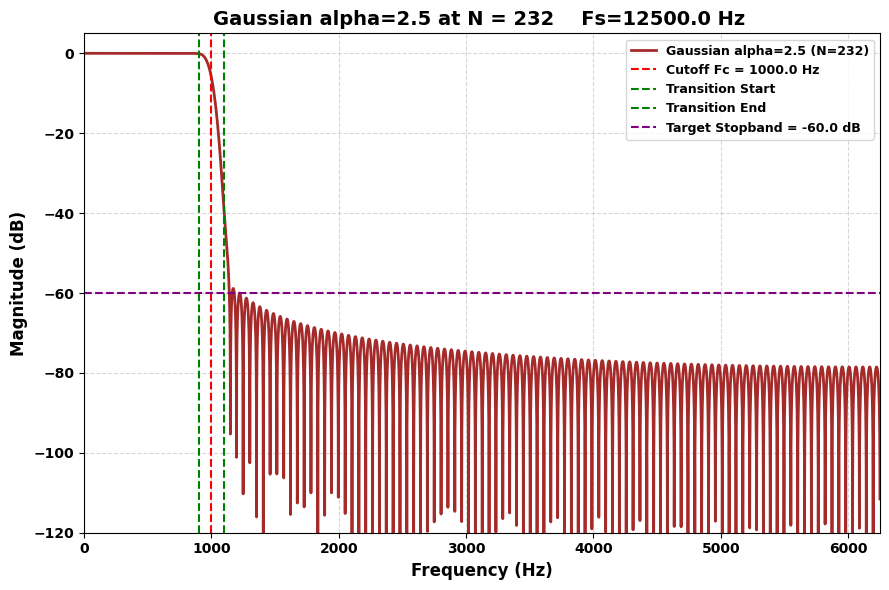

In [ ]:
plot_magnitude_response_single_window(
    Fc=1000.0,
    Fs=12500.0,
    Rp_target=0.05,
    As_target=60.0,
    N=232,
    tbw=200,
    window_name="Gaussian alpha=2.5"
)
